# EVCharge Intelligence
## A Predictive Analytics Framework for EV Charging Demand, Station Congestion and Customer Feedback Analysis

**Tool:** Google Colab / Python  
**Models:** Random Forest Regressor + Random Forest Classifier  
**BI Tool:** Power BI

### Project workflow
1. Load dataset
2. Clean and inspect data
3. Feature engineering
4. Exploratory data analysis
5. Predict EV charging demand
6. Predict station congestion
7. Analyze customer feedback
8. Evaluate models
9. Export prediction datasets for Power BI

## 1. Import Required Libraries

In [1]:
# Core data libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# Regression metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Classification metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the EV Charging Dataset

Upload the provided `EVCharge_Intelligence_Dataset.csv` file when Colab asks for it.

In [2]:
from google.colab import files

uploaded = files.upload()

FILE_NAME = next(iter(uploaded.keys()))

df = pd.read_csv(FILE_NAME)

df.columns = df.columns.str.strip()

print("Dataset loaded successfully")
print("File:", FILE_NAME)
print("Shape:", df.shape)

display(df.head())

Saving EVCharge_Intelligence_Dataset.csv to EVCharge_Intelligence_Dataset.csv
Dataset loaded successfully
File: EVCharge_Intelligence_Dataset.csv
Shape: (12000, 15)


,Timestamp,Station_ID,City,Connector_Type,Vehicle_Type,Temperature_C,Weather,Traffic_Level,Electricity_Price,Occupancy_Rate,Queue_Length,Energy_Demand_kWh,Customer_Rating,Feedback_Text,Customer_Sentiment
0,2025-03-16 10:15:00,CHE-ST-03,Chennai,DC Fast,Electric Taxi,33.3,Sunny,Low,9.41,46.4,1,17.89,3.9,Charging was fine but could be faster,Neutral
1,2025-05-21 00:29:00,CHE-ST-04,Chennai,AC,Sedan EV,25.7,Sunny,Medium,7.36,45.6,1,13.09,5.0,Very convenient charging station,Positive
2,2025-09-27 13:22:00,BEN-ST-02,Bengaluru,AC,SUV EV,25.1,Rainy,Medium,9.40,44.2,3,16.29,4.2,Good availability and helpful service,Positive
3,2025-08-25 03:15:00,BEN-ST-04,Bengaluru,AC,Hatchback EV,27.3,Rainy,Medium,8.42,46.3,4,12.32,4.0,Very convenient charging station,Positive
4,2025-12-30 12:41:00,BEN-ST-03,Bengaluru,AC,SUV EV,22.2,Stormy,Medium,8.18,36.8,0,19.68,4.3,Station was clean and easy to use,Positive


## 3. Validate the Dataset Structure

The project dataset contains charging activity, station information, environmental conditions, demand, congestion-related variables, and customer feedback.

In [3]:
expected_columns = [
    "Timestamp",
    "Station_ID",
    "City",
    "Connector_Type",
    "Vehicle_Type",
    "Temperature_C",
    "Weather",
    "Traffic_Level",
    "Electricity_Price",
    "Occupancy_Rate",
    "Queue_Length",
    "Energy_Demand_kWh",
    "Customer_Rating",
    "Feedback_Text",
    "Customer_Sentiment"
]

missing_columns = [c for c in expected_columns if c not in df.columns]
extra_columns = [c for c in df.columns if c not in expected_columns]

print("Expected columns:", len(expected_columns))
print("Available columns:", len(df.columns))
print("Missing columns:", missing_columns)
print("Extra columns:", extra_columns)

if missing_columns:
    raise ValueError("The uploaded file is missing required columns: " + str(missing_columns))

print("Dataset structure validated successfully.")

Expected columns: 15
Available columns: 15
Missing columns: []
Extra columns: []
Dataset structure validated successfully.


## 4. Understand the Data

In [4]:
print("========== DATASET INFORMATION ==========")
df.info()

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\n========== DUPLICATE ROWS ==========")
print(df.duplicated().sum())

print("\n========== NUMERICAL SUMMARY ==========")
display(df.describe().T)

print("\n========== CATEGORICAL SUMMARY ==========")
for col in ["Station_ID", "City", "Connector_Type", "Vehicle_Type", "Weather", "Traffic_Level", "Customer_Sentiment"]:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Timestamp           12000 non-null  object 
 1   Station_ID          12000 non-null  object 
 2   City                12000 non-null  object 
 3   Connector_Type      12000 non-null  object 
 4   Vehicle_Type        12000 non-null  object 
 5   Temperature_C       12000 non-null  float64
 6   Weather             12000 non-null  object 
 7   Traffic_Level       12000 non-null  object 
 8   Electricity_Price   12000 non-null  float64
 9   Occupancy_Rate      12000 non-null  float64
 10  Queue_Length        12000 non-null  int64  
 11  Energy_Demand_kWh   12000 non-null  float64
 12  Customer_Rating     12000 non-null  float64
 13  Feedback_Text       12000 non-null  object 
 14  Customer_Sentiment  12000 non-null  object 
dtypes: float64(

,count,mean,std,min,25%,50%,75%,max
Temperature_C,12000.0,26.696867,5.328389,7.3,23.10,27.05,30.5000,43.4
Electricity_Price,12000.0,9.248521,1.300525,7.0,8.12,9.24,10.3800,11.5
Occupancy_Rate,12000.0,52.229242,15.258707,10.5,41.40,50.85,61.9000,99.0
Queue_Length,12000.0,2.857917,2.224479,0.0,1.00,3.00,4.0000,11.0
Energy_Demand_kWh,12000.0,21.032817,8.526530,3.3,14.86,20.31,26.2025,58.0
Customer_Rating,12000.0,4.071025,0.748057,1.0,3.70,4.20,4.6000,5.0



========== CATEGORICAL SUMMARY ==========

Station_ID:
Station_ID
HYD-ST-04    532
HYD-ST-01    532
MUM-ST-02    531
CHE-ST-03    526
PUN-ST-03    514
CHE-ST-04    511
MUM-ST-04    511
BEN-ST-01    510
DEL-ST-03    509
BEN-ST-03    507
Name: count, dtype: int64

City:
City
Hyderabad    2036
Chennai      2015
Pune         2006
Bengaluru    2000
Delhi        1972
Mumbai       1971
Name: count, dtype: int64

Connector_Type:
Connector_Type
DC Fast          5711
AC               4346
DC Ultra Fast    1943
Name: count, dtype: int64

Vehicle_Type:
Vehicle_Type
Sedan EV                3583
SUV EV                  2728
Hatchback EV            2280
Electric Taxi           2144
Electric Two-Wheeler    1265
Name: count, dtype: int64

Weather:
Weather
Sunny     5057
Cloudy    3032
Rainy     2150
Fog        922
Stormy     839
Name: count, dtype: int64

Traffic_Level:
Traffic_Level
Low       4447
Medium    4405
High      3148
Name: count, dtype: int64

Customer_Sentiment:
Customer_Sentiment
Positive

## 5. Clean the Dataset

In [5]:
# Remove duplicate records
before = len(df)
df = df.drop_duplicates().copy()
after = len(df)

print("Rows before duplicate removal:", before)
print("Rows after duplicate removal :", after)
print("Duplicates removed           :", before - after)

# Convert timestamp
_df_timestamp = pd.to_datetime(df["Timestamp"], errors="coerce")
df["Timestamp"] = _df_timestamp

# Convert numerical columns explicitly
numeric_columns = [
    "Temperature_C",
    "Electricity_Price",
    "Occupancy_Rate",
    "Queue_Length",
    "Energy_Demand_kWh",
    "Customer_Rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Drop rows where the timestamp or target is unavailable
df = df.dropna(subset=["Timestamp", "Energy_Demand_kWh"]).copy()

# Fill numerical missing values with medians
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with the mode
categorical_columns = [
    "Station_ID",
    "City",
    "Connector_Type",
    "Vehicle_Type",
    "Weather",
    "Traffic_Level",
    "Customer_Sentiment"
]

for col in categorical_columns:
    mode = df[col].mode(dropna=True)
    fill_value = mode.iloc[0] if not mode.empty else "Unknown"
    df[col] = df[col].fillna(fill_value)

# Feedback text is treated as text, so fill missing values with an empty string
if "Feedback_Text" in df.columns:
    df["Feedback_Text"] = df["Feedback_Text"].fillna("").astype(str)

print("\nRemaining missing values:")
print(df.isnull().sum())

Rows before duplicate removal: 12000
Rows after duplicate removal : 12000
Duplicates removed           : 0

Remaining missing values:
Timestamp             0
Station_ID            0
City                  0
Connector_Type        0
Vehicle_Type          0
Temperature_C         0
Weather               0
Traffic_Level         0
Electricity_Price     0
Occupancy_Rate        0
Queue_Length          0
Energy_Demand_kWh     0
Customer_Rating       0
Feedback_Text         0
Customer_Sentiment    0
dtype: int64


## 6. Feature Engineering

Create time-based variables and a congestion label. The congestion label is derived from station occupancy and queue length. Those two fields will **not** be used as direct inputs to the congestion model, preventing target leakage.

In [6]:
# Time-based features

df["Year"] = df["Timestamp"].dt.year
df["Month"] = df["Timestamp"].dt.month
df["Day"] = df["Timestamp"].dt.day
df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

# Human-readable day name
_day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

df["Day_Name"] = df["DayOfWeek"].map(_day_names)

# Keep occupancy in percentage format
if df["Occupancy_Rate"].max() <= 1:
    df["Occupancy_Rate"] = df["Occupancy_Rate"] * 100

# Congestion definition
# High    : occupancy >= 80% OR queue >= 5
# Medium  : occupancy >= 50% OR queue >= 2
# Low     : otherwise

df["Congestion_Level"] = np.select(
    [
        (df["Occupancy_Rate"] >= 80) | (df["Queue_Length"] >= 5),
        (df["Occupancy_Rate"] >= 50) | (df["Queue_Length"] >= 2)
    ],
    ["High", "Medium"],
    default="Low"
)

# Feedback-related derived variables
rating_conditions = [
    df["Customer_Rating"] >= 4,
    df["Customer_Rating"] == 3,
    df["Customer_Rating"] <= 2
]

rating_choices = ["Positive", "Neutral", "Negative"]
df["Rating_Sentiment"] = np.select(rating_conditions, rating_choices, default="Unknown")
df["Feedback_Length"] = df["Feedback_Text"].astype(str).str.len()

print("Feature engineering completed.")
display(df.head())

Feature engineering completed.


,Timestamp,Station_ID,City,Connector_Type,Vehicle_Type,Temperature_C,Weather,Traffic_Level,Electricity_Price,Occupancy_Rate,Queue_Length,Energy_Demand_kWh,Customer_Rating,Feedback_Text,Customer_Sentiment,Year,Month,Day,Hour,DayOfWeek,IsWeekend,Day_Name,Congestion_Level,Rating_Sentiment,Feedback_Length
0,2025-03-16 10:15:00,CHE-ST-03,Chennai,DC Fast,Electric Taxi,33.3,Sunny,Low,9.41,46.4,1,17.89,3.9,Charging was fine but could be faster,Neutral,2025,3,16,10,6,1,Sunday,Low,Unknown,37
1,2025-05-21 00:29:00,CHE-ST-04,Chennai,AC,Sedan EV,25.7,Sunny,Medium,7.36,45.6,1,13.09,5.0,Very convenient charging station,Positive,2025,5,21,0,2,0,Wednesday,Low,Positive,32
2,2025-09-27 13:22:00,BEN-ST-02,Bengaluru,AC,SUV EV,25.1,Rainy,Medium,9.40,44.2,3,16.29,4.2,Good availability and helpful service,Positive,2025,9,27,13,5,1,Saturday,Medium,Positive,37
3,2025-08-25 03:15:00,BEN-ST-04,Bengaluru,AC,Hatchback EV,27.3,Rainy,Medium,8.42,46.3,4,12.32,4.0,Very convenient charging station,Positive,2025,8,25,3,0,0,Monday,Medium,Positive,32
4,2025-12-30 12:41:00,BEN-ST-03,Bengaluru,AC,SUV EV,22.2,Stormy,Medium,8.18,36.8,0,19.68,4.3,Station was clean and easy to use,Positive,2025,12,30,12,1,0,Tuesday,Low,Positive,33


## 7. Exploratory Data Analysis — Demand Distribution

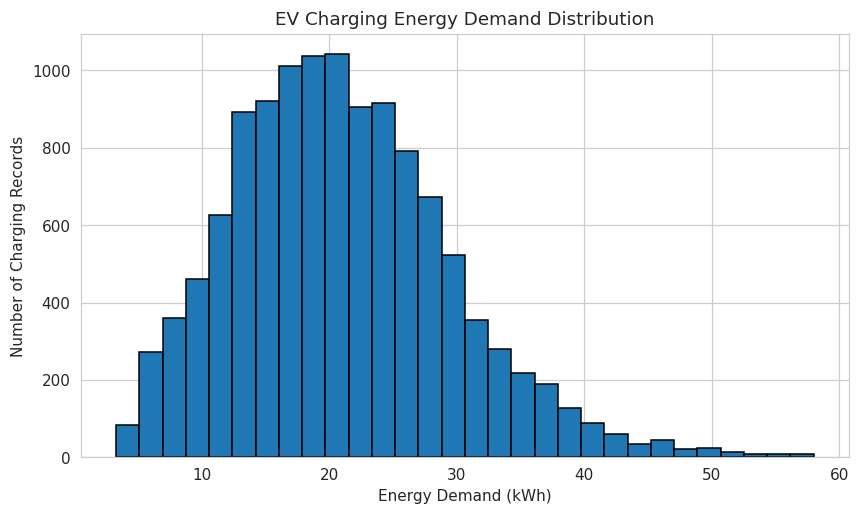

In [7]:
plt.figure(figsize=(9, 5))
plt.hist(df["Energy_Demand_kWh"], bins=30, edgecolor="black")
plt.title("EV Charging Energy Demand Distribution")
plt.xlabel("Energy Demand (kWh)")
plt.ylabel("Number of Charging Records")
plt.show()

## 8. Exploratory Data Analysis — Demand by Hour

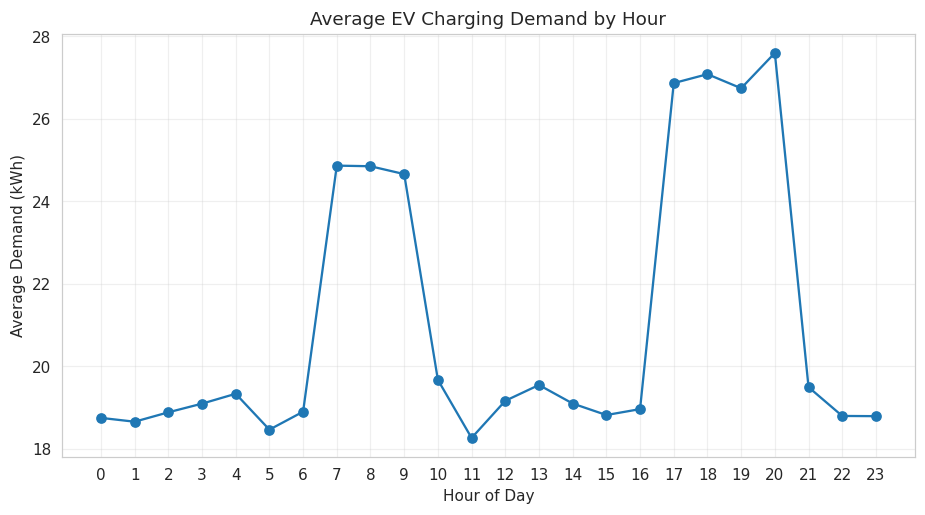

In [8]:
hourly_demand = (
    df.groupby("Hour")["Energy_Demand_kWh"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand["Hour"], hourly_demand["Energy_Demand_kWh"], marker="o")
plt.title("Average EV Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (kWh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

## 9. Exploratory Data Analysis — Demand by Traffic

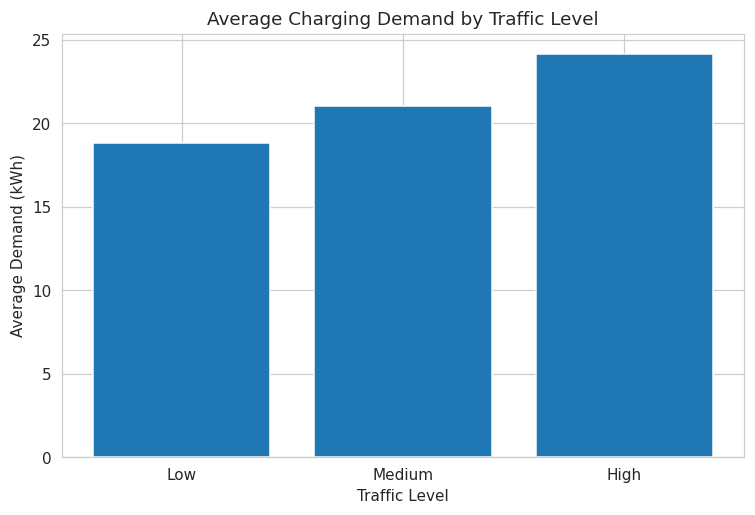

In [9]:
traffic_order = ["Low", "Medium", "High"]

traffic_demand = (
    df.groupby("Traffic_Level")["Energy_Demand_kWh"]
      .mean()
      .reindex(traffic_order)
)

plt.figure(figsize=(8, 5))
plt.bar(traffic_demand.index, traffic_demand.values)
plt.title("Average Charging Demand by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Demand (kWh)")
plt.show()

## 10. Exploratory Data Analysis — Station Congestion

Congestion distribution:
Congestion_Level
Low       3527
Medium    5711
High      2762
Name: count, dtype: int64


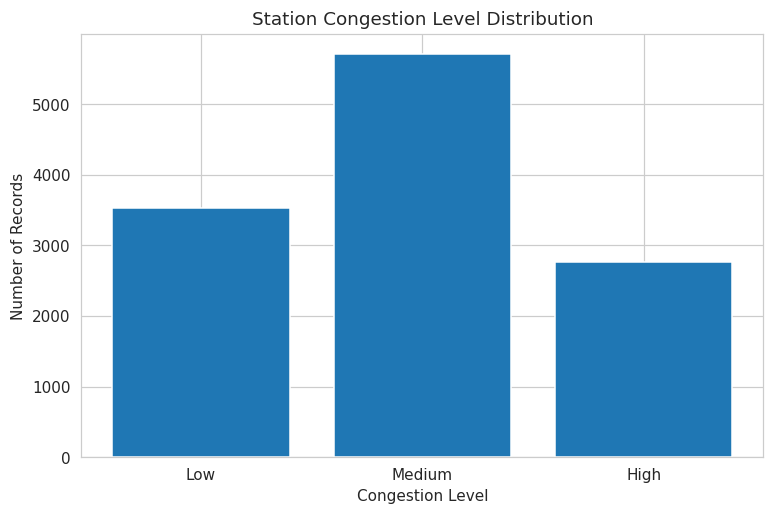

In [10]:
congestion_order = ["Low", "Medium", "High"]

print("Congestion distribution:")
print(df["Congestion_Level"].value_counts().reindex(congestion_order))

counts = df["Congestion_Level"].value_counts().reindex(congestion_order).fillna(0)
plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values)
plt.title("Station Congestion Level Distribution")
plt.xlabel("Congestion Level")
plt.ylabel("Number of Records")
plt.show()

## 11. Exploratory Data Analysis — Customer Feedback

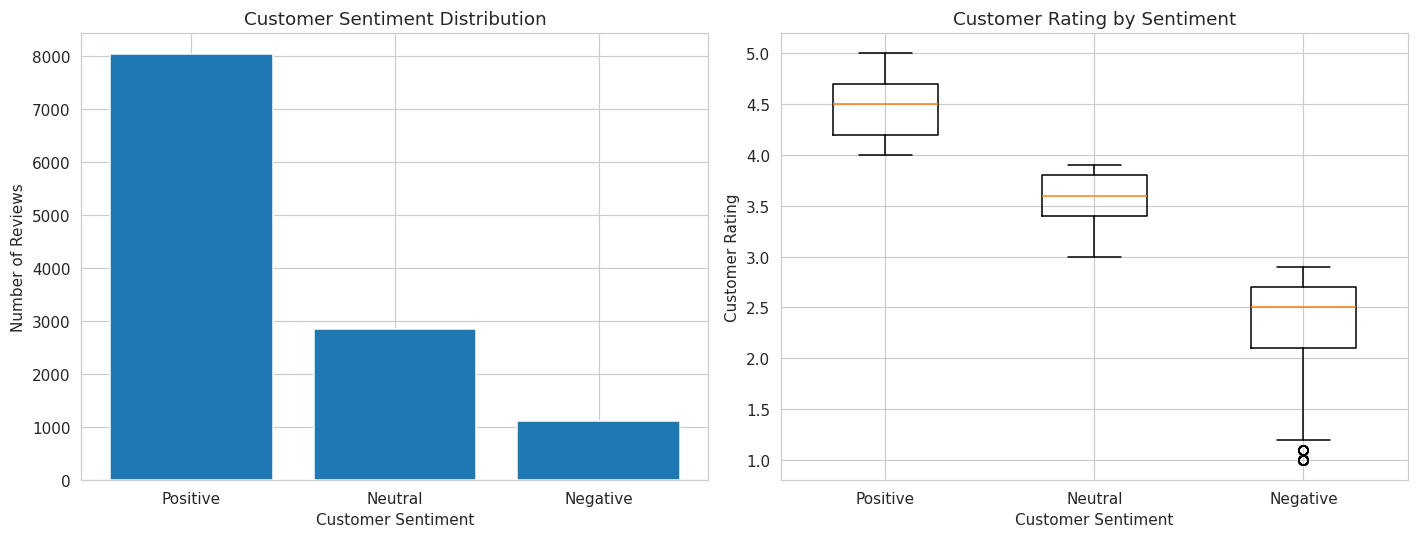

In [11]:
feedback_order = ["Positive", "Neutral", "Negative"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = df["Customer_Sentiment"].value_counts().reindex(feedback_order).fillna(0)
axes[0].bar(counts.index, counts.values)
axes[0].set_title("Customer Sentiment Distribution")
axes[0].set_xlabel("Customer Sentiment")
axes[0].set_ylabel("Number of Reviews")

for sentiment in feedback_order:
    values = df.loc[df["Customer_Sentiment"] == sentiment, "Customer_Rating"].dropna().values
    axes[1].boxplot(values, positions=[feedback_order.index(sentiment) + 1], widths=0.5)

axes[1].set_xticks(range(1, len(feedback_order) + 1))
axes[1].set_xticklabels(feedback_order)
axes[1].set_title("Customer Rating by Sentiment")
axes[1].set_xlabel("Customer Sentiment")
axes[1].set_ylabel("Customer Rating")

plt.tight_layout()
plt.show()

## 12. Correlation Heatmap

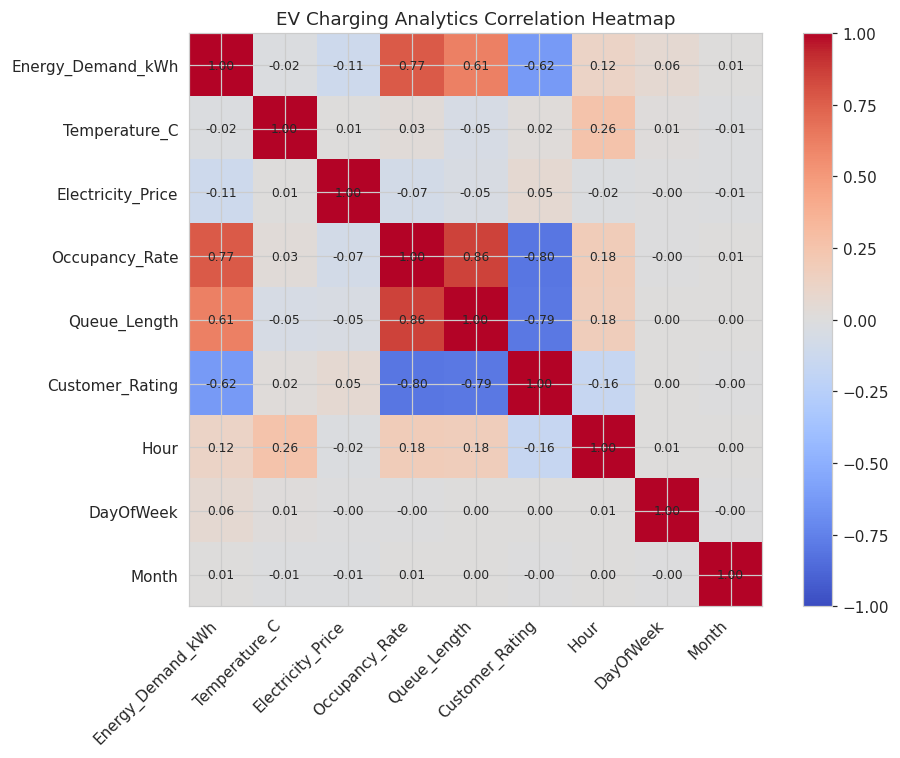

In [12]:
correlation_columns = [
    "Energy_Demand_kWh",
    "Temperature_C",
    "Electricity_Price",
    "Occupancy_Rate",
    "Queue_Length",
    "Customer_Rating",
    "Hour",
    "DayOfWeek",
    "Month"
]

corr = df[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("EV Charging Analytics Correlation Heatmap")
plt.tight_layout()
plt.show()

# 13. EV Charging Demand Prediction

**Target:** `Energy_Demand_kWh`  
**Algorithm:** Random Forest Regressor  
**Split:** 80% training, 20% testing

Station occupancy and queue length are excluded because they are strongly related to charging activity and could make the demand prediction unrealistically easy.

In [13]:
demand_features = [
    "Station_ID",
    "City",
    "Connector_Type",
    "Vehicle_Type",
    "Temperature_C",
    "Weather",
    "Traffic_Level",
    "Electricity_Price",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

demand_target = "Energy_Demand_kWh"

X_demand = df[demand_features].copy()
y_demand = df[demand_target].copy()

# Use the congestion label for stratification only.
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=df["Congestion_Level"]
)

X_train_d = X_demand.loc[train_idx].copy()
X_test_d = X_demand.loc[test_idx].copy()
y_train_d = y_demand.loc[train_idx].copy()
y_test_d = y_demand.loc[test_idx].copy()

print("Training samples:", len(X_train_d))
print("Testing samples :", len(X_test_d))

Training samples: 9600
Testing samples : 2400


## 14. Encode Demand Model Features

In [14]:
cat_demand = X_train_d.select_dtypes(exclude=np.number).columns.tolist()
num_demand = X_train_d.select_dtypes(include=np.number).columns.tolist()

demand_encoders = {}

# Numeric missing values
for col in num_demand:
    median_value = X_train_d[col].median()
    X_train_d[col] = X_train_d[col].fillna(median_value)
    X_test_d[col] = X_test_d[col].fillna(median_value)

# Categorical values using LabelEncoder, following the reference-project style
for col in cat_demand:
    X_train_d[col] = X_train_d[col].astype(str)
    X_test_d[col] = X_test_d[col].astype(str)

    fill_value = X_train_d[col].mode().iloc[0]
    X_train_d[col] = X_train_d[col].replace("nan", fill_value)
    X_test_d[col] = X_test_d[col].replace("nan", fill_value)

    le = LabelEncoder()
    X_train_d[col] = le.fit_transform(X_train_d[col])

    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    X_test_d[col] = X_test_d[col].map(mapping).fillna(-1)

    demand_encoders[col] = le

print("Encoded demand features:")
display(X_train_d.head())

Encoded demand features:


,Station_ID,City,Connector_Type,Vehicle_Type,Temperature_C,Weather,Traffic_Level,Electricity_Price,Hour,DayOfWeek,Month,IsWeekend
2465,6,1,0,4,27.7,4,0,7.58,8,6,7,1
8068,17,4,0,0,29.4,4,0,8.97,3,1,3,0
10515,15,3,1,0,22.2,3,1,7.77,19,4,2,0
8659,23,5,1,1,25.9,0,0,11.33,18,6,8,1
9353,11,2,1,3,28.0,0,1,8.82,11,4,8,0


## 15. Train Random Forest Regressor

In [15]:
demand_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

demand_model.fit(X_train_d, y_train_d)

demand_predictions = demand_model.predict(X_test_d)

print("Random Forest demand model trained successfully.")

Random Forest demand model trained successfully.


## 16. Evaluate Charging Demand Prediction

In [16]:
demand_mae = mean_absolute_error(y_test_d, demand_predictions)
demand_rmse = np.sqrt(mean_squared_error(y_test_d, demand_predictions))
demand_r2 = r2_score(y_test_d, demand_predictions)

print("========== DEMAND MODEL RESULTS ==========")
print(f"MAE : {demand_mae:.2f} kWh")
print(f"RMSE: {demand_rmse:.2f} kWh")
print(f"R2  : {demand_r2:.3f}")

========== DEMAND MODEL RESULTS ==========
MAE : 2.52 kWh
RMSE: 3.34 kWh
R2  : 0.847


## 17. Actual vs Predicted Charging Demand

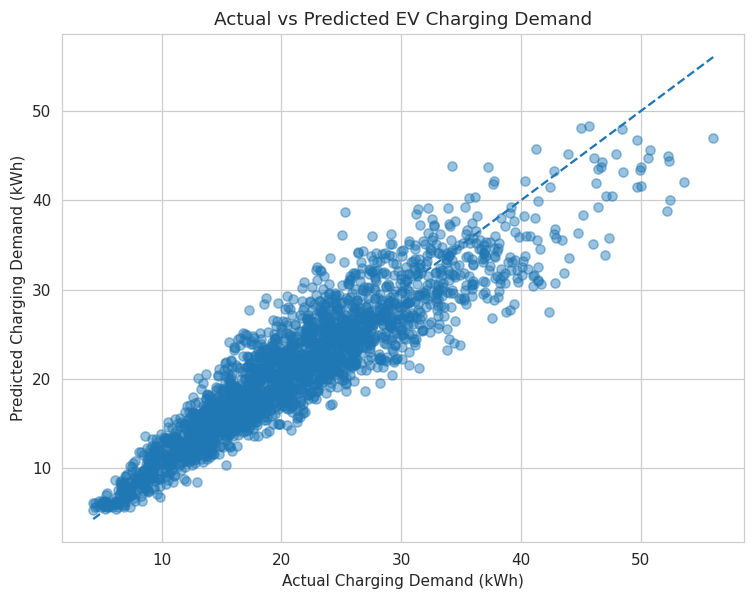

In [17]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_d, demand_predictions, alpha=0.45)

line_min = min(y_test_d.min(), demand_predictions.min())
line_max = max(y_test_d.max(), demand_predictions.max())

plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")

plt.xlabel("Actual Charging Demand (kWh)")
plt.ylabel("Predicted Charging Demand (kWh)")
plt.title("Actual vs Predicted EV Charging Demand")
plt.show()

## 18. Demand Model Feature Importance

,Feature,Importance
3,Vehicle_Type,0.350509
2,Connector_Type,0.316384
8,Hour,0.104318
6,Traffic_Level,0.056880
7,Electricity_Price,0.050008
4,Temperature_C,0.031736
0,Station_ID,0.031159
10,Month,0.018891
9,DayOfWeek,0.014757
1,City,0.013331


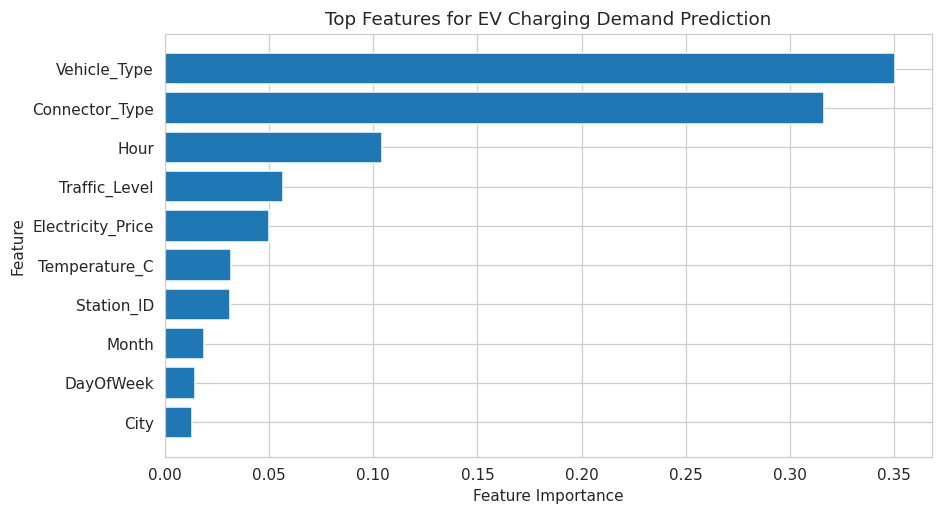

In [18]:
demand_importance = pd.DataFrame({
    "Feature": X_train_d.columns,
    "Importance": demand_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(demand_importance)

top_demand = demand_importance.head(10).sort_values("Importance")
plt.figure(figsize=(9, 5))
plt.barh(top_demand["Feature"], top_demand["Importance"])
plt.title("Top Features for EV Charging Demand Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

## 19. Generate Demand Predictions for All Records

The model is trained only on the training portion, then used to score the full dataset so the resulting file can be explored in Power BI.

In [19]:
X_all_d = X_demand.copy()

# Apply the same encoding learned from training data
for col in cat_demand:
    le = demand_encoders[col]
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    X_all_d[col] = X_all_d[col].astype(str).map(mapping).fillna(-1)

for col in num_demand:
    X_all_d[col] = X_all_d[col].fillna(X_train_d[col].median())

df["Predicted_Demand_kWh"] = demand_model.predict(X_all_d).round(2)

df["Demand_Error_kWh"] = (
    df["Predicted_Demand_kWh"] - df["Energy_Demand_kWh"]
).round(2)

df["Absolute_Demand_Error_kWh"] = df["Demand_Error_kWh"].abs().round(2)

# Demand-risk bands based on prediction distribution
q1, q2 = df["Predicted_Demand_kWh"].quantile([0.33, 0.66])

df["Demand_Risk"] = pd.cut(
    df["Predicted_Demand_kWh"],
    bins=[-np.inf, q1, q2, np.inf],
    labels=["Low", "Medium", "High"]
)

display(
    df[[
        "Energy_Demand_kWh",
        "Predicted_Demand_kWh",
        "Demand_Error_kWh",
        "Demand_Risk"
    ]].head()
)

,Energy_Demand_kWh,Predicted_Demand_kWh,Demand_Error_kWh,Demand_Risk
0,17.89,21.15,3.26,Medium
1,13.09,13.27,0.18,Low
2,16.29,17.27,0.98,Medium
3,12.32,11.64,-0.68,Low
4,19.68,19.64,-0.04,Medium


# 20. Station Congestion Prediction

**Target:** `Congestion_Level` with classes Low / Medium / High.  
The target is derived from occupancy and queue length, but those two variables are not used as direct model inputs. This keeps the prediction task more realistic.

In [20]:
congestion_features = [
    "Station_ID",
    "City",
    "Connector_Type",
    "Vehicle_Type",
    "Temperature_C",
    "Weather",
    "Traffic_Level",
    "Electricity_Price",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "Predicted_Demand_kWh"
]

X_congestion = df[congestion_features].copy()
y_congestion = df["Congestion_Level"].copy()

X_train_c = X_congestion.loc[train_idx].copy()
X_test_c = X_congestion.loc[test_idx].copy()
y_train_c = y_congestion.loc[train_idx].copy()
y_test_c = y_congestion.loc[test_idx].copy()

print("Congestion training samples:", len(X_train_c))
print("Congestion testing samples :", len(X_test_c))

Congestion training samples: 9600
Congestion testing samples : 2400


## 21. Encode Congestion Model Features

In [21]:
cat_congestion = X_train_c.select_dtypes(exclude=np.number).columns.tolist()
num_congestion = X_train_c.select_dtypes(include=np.number).columns.tolist()

congestion_encoders = {}

for col in num_congestion:
    median_value = X_train_c[col].median()
    X_train_c[col] = X_train_c[col].fillna(median_value)
    X_test_c[col] = X_test_c[col].fillna(median_value)

for col in cat_congestion:
    X_train_c[col] = X_train_c[col].astype(str)
    X_test_c[col] = X_test_c[col].astype(str)

    fill_value = X_train_c[col].mode().iloc[0]
    X_train_c[col] = X_train_c[col].replace("nan", fill_value)
    X_test_c[col] = X_test_c[col].replace("nan", fill_value)

    le = LabelEncoder()
    X_train_c[col] = le.fit_transform(X_train_c[col])

    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    X_test_c[col] = X_test_c[col].map(mapping).fillna(-1)

    congestion_encoders[col] = le

# Encode the target classes
congestion_target_encoder = LabelEncoder()
y_train_c_encoded = congestion_target_encoder.fit_transform(y_train_c)

print("Congestion classes:")
print(congestion_target_encoder.classes_)

Congestion classes:
['High' 'Low' 'Medium']


## 22. Train Random Forest Classifier

In [22]:
congestion_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

congestion_model.fit(X_train_c, y_train_c_encoded)

congestion_predictions_encoded = congestion_model.predict(X_test_c)
congestion_predictions = congestion_target_encoder.inverse_transform(
    congestion_predictions_encoded
)

print("Random Forest congestion model trained successfully.")

Random Forest congestion model trained successfully.


## 23. Evaluate Congestion Prediction

In [23]:
congestion_accuracy = accuracy_score(y_test_c, congestion_predictions)
congestion_precision = precision_score(
    y_test_c,
    congestion_predictions,
    average="weighted",
    zero_division=0
)
congestion_recall = recall_score(
    y_test_c,
    congestion_predictions,
    average="weighted",
    zero_division=0
)
congestion_f1 = f1_score(
    y_test_c,
    congestion_predictions,
    average="weighted",
    zero_division=0
)

print("========== CONGESTION MODEL RESULTS ==========")
print(f"Accuracy : {congestion_accuracy:.3f}")
print(f"Precision: {congestion_precision:.3f}")
print(f"Recall   : {congestion_recall:.3f}")
print(f"F1 Score : {congestion_f1:.3f}")

print("\nClassification Report:")
print(classification_report(y_test_c, congestion_predictions, zero_division=0))

========== CONGESTION MODEL RESULTS ==========
Accuracy : 0.680
Precision: 0.685
Recall   : 0.680
F1 Score : 0.679

Classification Report:
              precision    recall  f1-score   support

        High       0.76      0.66      0.71       553
         Low       0.69      0.59      0.64       705
      Medium       0.64      0.74      0.69      1142

    accuracy                           0.68      2400
   macro avg       0.70      0.67      0.68      2400
weighted avg       0.69      0.68      0.68      2400



## 24. Congestion Confusion Matrix

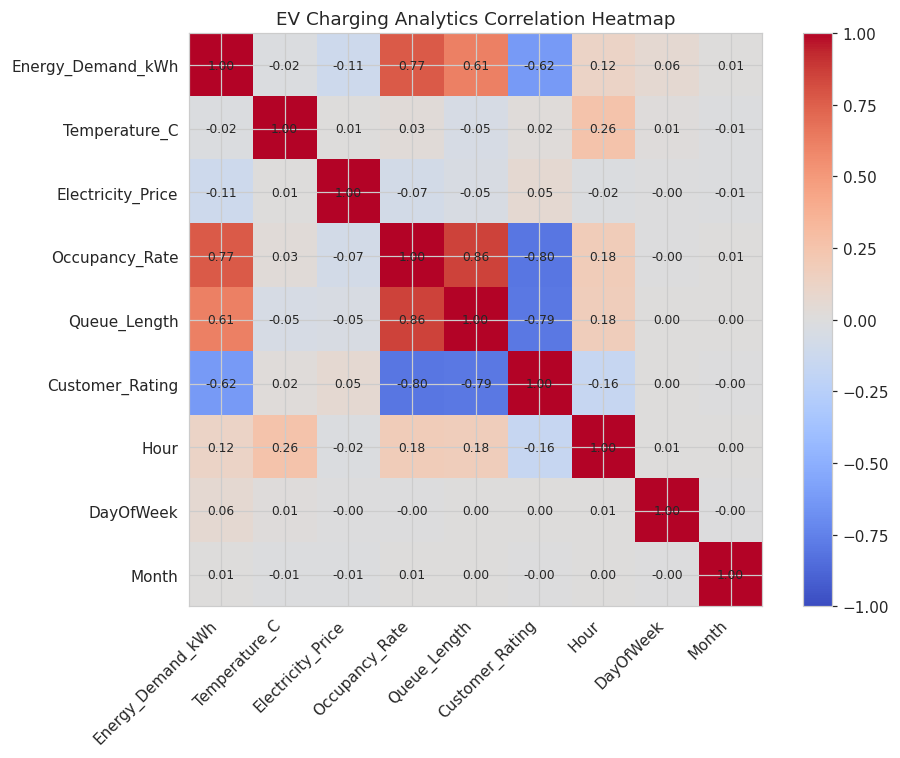

In [24]:
correlation_columns = [
    "Energy_Demand_kWh",
    "Temperature_C",
    "Electricity_Price",
    "Occupancy_Rate",
    "Queue_Length",
    "Customer_Rating",
    "Hour",
    "DayOfWeek",
    "Month"
]

corr = df[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("EV Charging Analytics Correlation Heatmap")
plt.tight_layout()
plt.show()

## 25. Congestion Feature Importance

,Feature,Importance
12,Predicted_Demand_kWh,0.230046
6,Traffic_Level,0.216805
8,Hour,0.089429
4,Temperature_C,0.088264
7,Electricity_Price,0.085699
0,Station_ID,0.059766
10,Month,0.056777
9,DayOfWeek,0.041817
3,Vehicle_Type,0.032238
5,Weather,0.030408


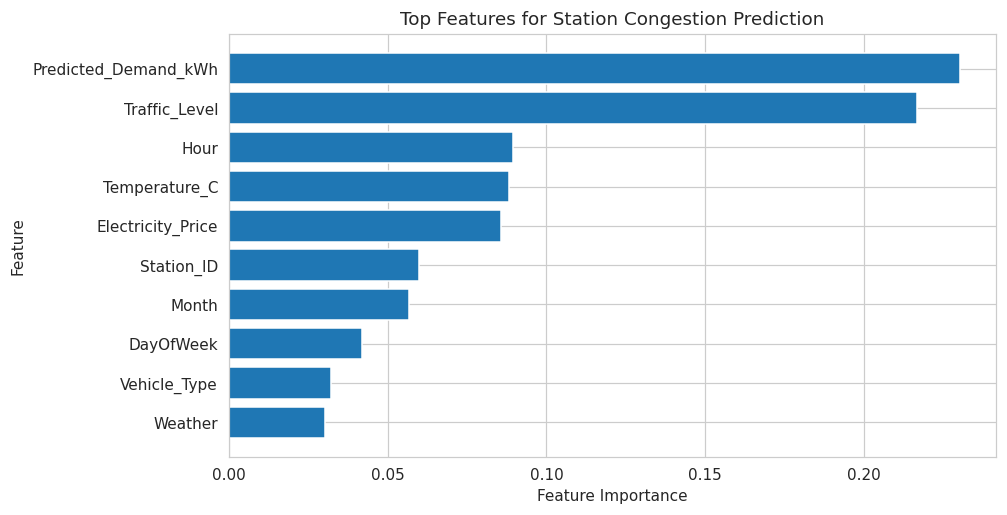

In [25]:
congestion_importance = pd.DataFrame({
    "Feature": X_train_c.columns,
    "Importance": congestion_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(congestion_importance)

top_congestion = congestion_importance.head(10).sort_values("Importance")
plt.figure(figsize=(9, 5))
plt.barh(top_congestion["Feature"], top_congestion["Importance"])
plt.title("Top Features for Station Congestion Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

## 26. Generate Congestion Predictions for All Records

In [26]:
X_all_c = X_congestion.copy()

for col in cat_congestion:
    le = congestion_encoders[col]
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    X_all_c[col] = X_all_c[col].astype(str).map(mapping).fillna(-1)

for col in num_congestion:
    X_all_c[col] = X_all_c[col].fillna(X_train_c[col].median())

all_congestion_encoded = congestion_model.predict(X_all_c)

df["Predicted_Congestion"] = congestion_target_encoder.inverse_transform(
    all_congestion_encoded
)

df["Congestion_Correct"] = np.where(
    df["Congestion_Level"].astype(str) == df["Predicted_Congestion"].astype(str),
    "Yes",
    "No"
)

display(
    df[[
        "Congestion_Level",
        "Predicted_Congestion",
        "Congestion_Correct"
    ]].head(10)
)

,Congestion_Level,Predicted_Congestion,Congestion_Correct
0,Low,Medium,No
1,Low,Low,Yes
2,Medium,Medium,Yes
3,Medium,Low,No
4,Low,Low,Yes
5,Medium,Medium,Yes
6,High,High,Yes
7,Medium,Medium,Yes
8,Low,Low,Yes
9,Medium,Medium,Yes


# 27. Customer Feedback Analysis

Customer sentiment is already available in the supplied dataset. Here we summarize the feedback, ratings and station-level customer experience rather than building a text classifier.

In [27]:
feedback_summary = (
    df.groupby("Customer_Sentiment")
      .agg(
          Feedback_Count=("Customer_Sentiment", "size"),
          Average_Rating=("Customer_Rating", "mean")
      )
      .reindex(["Positive", "Neutral", "Negative"])
      .reset_index()
)

feedback_summary["Average_Rating"] = feedback_summary["Average_Rating"].round(2)

display(feedback_summary)

station_feedback = (
    df.groupby("Station_ID")
      .agg(
          Feedback_Count=("Customer_Rating", "size"),
          Average_Rating=("Customer_Rating", "mean"),
          Negative_Feedback=("Customer_Sentiment", lambda x: (x == "Negative").sum())
      )
      .reset_index()
)

station_feedback["Negative_Feedback_%"] = (
    station_feedback["Negative_Feedback"] /
    station_feedback["Feedback_Count"] * 100
).round(2)

print("Stations with lowest average customer rating:")
display(station_feedback.sort_values("Average_Rating").head(10))

,Customer_Sentiment,Feedback_Count,Average_Rating
0,Positive,8026,4.49
1,Neutral,2854,3.56
2,Negative,1120,2.35


Stations with lowest average customer rating:


,Station_ID,Feedback_Count,Average_Rating,Negative_Feedback,Negative_Feedback_%
10,DEL-ST-03,509,3.908644,81,15.91
9,DEL-ST-02,490,3.946735,63,12.86
18,MUM-ST-03,477,3.948008,64,13.42
8,DEL-ST-01,489,3.957055,55,11.25
11,DEL-ST-04,484,3.997934,64,13.22
17,MUM-ST-02,531,3.998493,62,11.68
19,MUM-ST-04,511,4.001957,61,11.94
16,MUM-ST-01,452,4.021903,48,10.62
2,BEN-ST-03,507,4.043590,57,11.24
1,BEN-ST-02,498,4.050803,44,8.84


## 28. Feedback and Congestion Relationship

In [28]:
feedback_congestion = (
    df.groupby("Congestion_Level")
      .agg(
          Average_Rating=("Customer_Rating", "mean"),
          Negative_Feedback_Percent=(
              "Customer_Sentiment",
              lambda x: (x == "Negative").mean() * 100
          ),
          Records=("Customer_Rating", "size")
      )
      .reindex(["Low", "Medium", "High"])
      .reset_index()
)

feedback_congestion["Average_Rating"] = feedback_congestion["Average_Rating"].round(2)
feedback_congestion["Negative_Feedback_Percent"] = feedback_congestion["Negative_Feedback_Percent"].round(2)

display(feedback_congestion)

,Congestion_Level,Average_Rating,Negative_Feedback_Percent,Records
0,Low,4.58,0.03,3527
1,Medium,4.23,0.58,5711
2,High,3.10,39.32,2762


# 29. Prepare Power BI Dataset

This output is the main file for the Power BI dashboard. It keeps the original business fields and adds the model predictions, errors, demand risk, congestion predictions and customer sentiment.

In [29]:
powerbi_columns = [
    "Timestamp",
    "Station_ID",
    "City",
    "Connector_Type",
    "Vehicle_Type",
    "Temperature_C",
    "Weather",
    "Traffic_Level",
    "Electricity_Price",
    "Occupancy_Rate",
    "Queue_Length",
    "Energy_Demand_kWh",
    "Predicted_Demand_kWh",
    "Demand_Error_kWh",
    "Absolute_Demand_Error_kWh",
    "Demand_Risk",
    "Congestion_Level",
    "Predicted_Congestion",
    "Congestion_Correct",
    "Customer_Rating",
    "Customer_Sentiment",
    "Rating_Sentiment",
    "Feedback_Text",
    "Feedback_Length",
    "Year",
    "Month",
    "Day",
    "Hour",
    "DayOfWeek",
    "Day_Name",
    "IsWeekend"
]

powerbi = df[powerbi_columns].copy()

# Convert categorical risk values to text for a clean CSV export
powerbi["Demand_Risk"] = powerbi["Demand_Risk"].astype(str)

print("Power BI dataset shape:", powerbi.shape)
display(powerbi.head())

Power BI dataset shape: (12000, 31)


,Timestamp,Station_ID,City,Connector_Type,Vehicle_Type,Temperature_C,Weather,Traffic_Level,Electricity_Price,Occupancy_Rate,Queue_Length,Energy_Demand_kWh,Predicted_Demand_kWh,Demand_Error_kWh,Absolute_Demand_Error_kWh,Demand_Risk,Congestion_Level,Predicted_Congestion,Congestion_Correct,Customer_Rating,Customer_Sentiment,Rating_Sentiment,Feedback_Text,Feedback_Length,Year,Month,Day,Hour,DayOfWeek,Day_Name,IsWeekend
0,2025-03-16 10:15:00,CHE-ST-03,Chennai,DC Fast,Electric Taxi,33.3,Sunny,Low,9.41,46.4,1,17.89,21.15,3.26,3.26,Medium,Low,Medium,No,3.9,Neutral,Unknown,Charging was fine but could be faster,37,2025,3,16,10,6,Sunday,1
1,2025-05-21 00:29:00,CHE-ST-04,Chennai,AC,Sedan EV,25.7,Sunny,Medium,7.36,45.6,1,13.09,13.27,0.18,0.18,Low,Low,Low,Yes,5.0,Positive,Positive,Very convenient charging station,32,2025,5,21,0,2,Wednesday,0
2,2025-09-27 13:22:00,BEN-ST-02,Bengaluru,AC,SUV EV,25.1,Rainy,Medium,9.40,44.2,3,16.29,17.27,0.98,0.98,Medium,Medium,Medium,Yes,4.2,Positive,Positive,Good availability and helpful service,37,2025,9,27,13,5,Saturday,1
3,2025-08-25 03:15:00,BEN-ST-04,Bengaluru,AC,Hatchback EV,27.3,Rainy,Medium,8.42,46.3,4,12.32,11.64,-0.68,0.68,Low,Medium,Low,No,4.0,Positive,Positive,Very convenient charging station,32,2025,8,25,3,0,Monday,0
4,2025-12-30 12:41:00,BEN-ST-03,Bengaluru,AC,SUV EV,22.2,Stormy,Medium,8.18,36.8,0,19.68,19.64,-0.04,0.04,Medium,Low,Low,Yes,4.3,Positive,Positive,Station was clean and easy to use,33,2025,12,30,12,1,Tuesday,0


## 30. Create Station-Level Summary for Power BI

In [30]:
station_summary = (
    powerbi.groupby("Station_ID")
           .agg(
               City=("City", "first"),
               Total_Records=("Station_ID", "size"),
               Average_Actual_Demand_kWh=("Energy_Demand_kWh", "mean"),
               Average_Predicted_Demand_kWh=("Predicted_Demand_kWh", "mean"),
               Average_Occupancy=("Occupancy_Rate", "mean"),
               Average_Queue=("Queue_Length", "mean"),
               Average_Customer_Rating=("Customer_Rating", "mean"),
               High_Congestion_Records=("Predicted_Congestion", lambda x: (x == "High").sum()),
               Negative_Feedback_Records=("Customer_Sentiment", lambda x: (x == "Negative").sum())
           )
           .reset_index()
)

station_summary["Average_Actual_Demand_kWh"] = station_summary["Average_Actual_Demand_kWh"].round(2)
station_summary["Average_Predicted_Demand_kWh"] = station_summary["Average_Predicted_Demand_kWh"].round(2)
station_summary["Average_Occupancy"] = station_summary["Average_Occupancy"].round(2)
station_summary["Average_Queue"] = station_summary["Average_Queue"].round(2)
station_summary["Average_Customer_Rating"] = station_summary["Average_Customer_Rating"].round(2)

station_summary["High_Congestion_%"] = (
    station_summary["High_Congestion_Records"] /
    station_summary["Total_Records"] * 100
).round(2)

station_summary["Negative_Feedback_%"] = (
    station_summary["Negative_Feedback_Records"] /
    station_summary["Total_Records"] * 100
).round(2)

display(station_summary.head(10))

,Station_ID,City,Total_Records,Average_Actual_Demand_kWh,Average_Predicted_Demand_kWh,Average_Occupancy,Average_Queue,Average_Customer_Rating,High_Congestion_Records,Negative_Feedback_Records,High_Congestion_%,Negative_Feedback_%
0,BEN-ST-01,Bengaluru,510,21.08,20.90,51.79,2.76,4.10,107,48,20.98,9.41
1,BEN-ST-02,Bengaluru,498,22.09,21.93,53.04,2.93,4.05,122,44,24.50,8.84
2,BEN-ST-03,Bengaluru,507,22.17,21.54,53.42,2.92,4.04,122,57,24.06,11.24
3,BEN-ST-04,Bengaluru,485,21.21,21.36,52.68,2.86,4.07,115,44,23.71,9.07
4,CHE-ST-01,Chennai,481,19.00,19.59,50.52,2.69,4.12,89,32,18.50,6.65
5,CHE-ST-02,Chennai,497,17.67,18.53,47.50,2.31,4.21,82,25,16.50,5.03
6,CHE-ST-03,Chennai,526,18.57,19.25,50.44,2.75,4.15,109,42,20.72,7.98
7,CHE-ST-04,Chennai,511,18.88,19.45,50.11,2.52,4.16,93,31,18.20,6.07
8,DEL-ST-01,Delhi,489,23.40,22.77,55.40,3.26,3.96,130,55,26.58,11.25
9,DEL-ST-02,Delhi,490,24.47,23.56,55.78,3.13,3.95,126,63,25.71,12.86


## 31. Save Model Metrics

In [31]:
metrics = pd.DataFrame({
    "Model": [
        "Random Forest Regressor",
        "Random Forest Classifier"
    ],
    "Task": [
        "EV Charging Demand",
        "Station Congestion"
    ],
    "MAE": [
        demand_mae,
        np.nan
    ],
    "RMSE": [
        demand_rmse,
        np.nan
    ],
    "R2": [
        demand_r2,
        np.nan
    ],
    "Accuracy": [
        np.nan,
        congestion_accuracy
    ],
    "Precision": [
        np.nan,
        congestion_precision
    ],
    "Recall": [
        np.nan,
        congestion_recall
    ],
    "F1_Score": [
        np.nan,
        congestion_f1
    ]
})

metrics.to_csv("EVCharge_Model_Metrics.csv", index=False)
display(metrics.round(4))

,Model,Task,MAE,RMSE,R2,Accuracy,Precision,Recall,F1_Score
0,Random Forest Regressor,EV Charging Demand,2.5229,3.3425,0.8468,NaN,NaN,NaN,NaN
1,Random Forest Classifier,Station Congestion,NaN,NaN,NaN,0.68,0.6854,0.68,0.6792


## 32. Save Feature Importance

In [32]:
demand_importance_export = demand_importance.copy()
demand_importance_export["Model_Task"] = "EV Charging Demand"

demand_importance_export = demand_importance_export[
    ["Model_Task", "Feature", "Importance"]
]

congestion_importance_export = congestion_importance.copy()
congestion_importance_export["Model_Task"] = "Station Congestion"

congestion_importance_export = congestion_importance_export[
    ["Model_Task", "Feature", "Importance"]
]

feature_importance = pd.concat(
    [demand_importance_export, congestion_importance_export],
    ignore_index=True
)

feature_importance.to_csv(
    "EVCharge_Feature_Importance.csv",
    index=False
)

display(feature_importance.head(20))

,Model_Task,Feature,Importance
0,EV Charging Demand,Vehicle_Type,0.350509
1,EV Charging Demand,Connector_Type,0.316384
2,EV Charging Demand,Hour,0.104318
3,EV Charging Demand,Traffic_Level,0.056880
4,EV Charging Demand,Electricity_Price,0.050008
5,EV Charging Demand,Temperature_C,0.031736
6,EV Charging Demand,Station_ID,0.031159
7,EV Charging Demand,Month,0.018891
8,EV Charging Demand,DayOfWeek,0.014757
9,EV Charging Demand,City,0.013331


## 33. Export All Power BI Files

In [33]:
powerbi.to_csv(
    "EVCharge_PowerBI_Predictions.csv",
    index=False
)

station_summary.to_csv(
    "EVCharge_Station_Summary.csv",
    index=False
)

print("Files created successfully:")
print("1. EVCharge_PowerBI_Predictions.csv")
print("2. EVCharge_Station_Summary.csv")
print("3. EVCharge_Model_Metrics.csv")
print("4. EVCharge_Feature_Importance.csv")

Files created successfully:
1. EVCharge_PowerBI_Predictions.csv
2. EVCharge_Station_Summary.csv
3. EVCharge_Model_Metrics.csv
4. EVCharge_Feature_Importance.csv


## 34. Download the Output Files from Colab

In [34]:
from google.colab import files

files.download("EVCharge_PowerBI_Predictions.csv")
# Run the following separately when needed:
# files.download("EVCharge_Station_Summary.csv")
# files.download("EVCharge_Model_Metrics.csv")
# files.download("EVCharge_Feature_Importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# End of Python / Colab Part

### Power BI inputs produced by this notebook

- **EVCharge_PowerBI_Predictions.csv** — main dashboard dataset
- **EVCharge_Station_Summary.csv** — station-level performance summary
- **EVCharge_Model_Metrics.csv** — regression and classification metrics
- **EVCharge_Feature_Importance.csv** — model feature importance

The next project stage is to import these outputs into Power BI and build the EVCharge Intelligence dashboard with KPI cards, demand trends, congestion analysis, customer feedback analysis, station comparisons and slicers.